In [24]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = ("cuda" if torch.cuda.is_available() else "cpu")

In [25]:
transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

In [26]:
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [27]:
class DummyMNIST(nn.Module):
    def __init__(self, counts):
        super().__init__()

        probabilities = counts.float() / counts.sum()

        self.register_buffer(
            "logits", torch.log(probabilities)
        )

    def forward(self, x):
        return self.logits.unsqueeze(0).expand(x.size(0), -1)

In [28]:
counts = torch.bincount(
    train_data.targets,
    minlength=10,
)

dummy = DummyMNIST(counts).to(device)

In [29]:
class ModelMNIST(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.network(x)

In [30]:
model = ModelMNIST().to(device)
print(model)

ModelMNIST(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): ReLU()
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [31]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [32]:
def fit(epochs=5):
    model.train()

    for epoch in range(epochs):
        total = 0
        correct = 0
        total_loss = 0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)

            predictions = model(X)
            loss = criterion(predictions, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() + X.size(0)
            predicted = predictions.argmax(dim=1)
            correct += (predicted == y).sum().item()
            total += y.size(0)

        avg_loss = total_loss / total
        accuracy = correct / total

        print(f"Epoch: {epoch + 1}/{epochs} | Loss: {avg_loss} | Accuracy: {accuracy}")

In [33]:
fit()

Epoch: 1/5 | Loss: 1.0046421783003645 | Accuracy: 0.9128833333333334
Epoch: 2/5 | Loss: 1.001691263343681 | Accuracy: 0.9674833333333334
Epoch: 3/5 | Loss: 1.0011542786822498 | Accuracy: 0.9769
Epoch: 4/5 | Loss: 1.000849627154204 | Accuracy: 0.9824166666666667
Epoch: 5/5 | Loss: 1.0006412330076146 | Accuracy: 0.9865166666666667


In [34]:
def evaluating(model=model):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for X, y in test_loader:
            X, y = X.to(device), y.to(device)
            predictions = model(X)

            predicted_classes = predictions.argmax(dim=1)
            correct += (predicted_classes == y).sum().item()
            total += y.size(0)

    print("Accuracy:", correct / total)

In [35]:
evaluating(model)
evaluating(dummy)

Accuracy: 0.9735
Accuracy: 0.1135


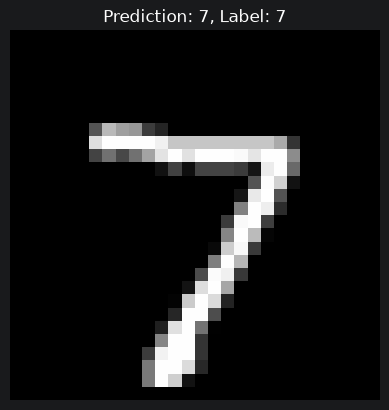

In [36]:
import matplotlib.pyplot as plt

image, label = test_data[0]
model.eval()

with torch.no_grad():
    prediction = model(image.unsqueeze(0).to(device))

predicted_digit = prediction.argmax(dim=1).item()

plt.imshow(image.squeeze().numpy(), cmap="gray")
plt.title(f"Prediction: {predicted_digit}, Label: {label}")
plt.axis("off")
plt.show()